<a href="https://colab.research.google.com/github/Yohannes264/231111676_YohannesCorneliusWillifredis/blob/master/notebook/churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Project Identification

- **Judul:** Prediksi Churn Pelanggan Telekomunikasi
- **Domain:** *Customer Analytics* pada industri telekomunikasi
- **Stakeholder:** Pelanggan (*Customers*) dan Tim Manajemen Produk & Retensi
- **Sumber Data:** IBM Sample Data Sets (*Telco Customer Churn*), 7.043 pelanggan dan 21 atribut
- **Latar Belakang:** Mengapa mendeteksi pelanggan yang akan berhenti berlangganan itu penting bagi perusahaan telekomunikasi? Ada 3 faktor utama:
  1. Pendapatan utama perusahaan telekomunikasi bergantung pada stabilitas pelanggan berlangganan.
  2. Biaya mengakuisisi pelanggan baru jauh lebih mahal dibandingkan mempertahankan pelanggan yang sudah ada.
  3. Lebih baik mencegah secara proaktif daripada kehilangan pelanggan secara reaktif.


## 2. Problem Formulation

- **Problem:** Bagaimana memprediksi apakah seorang pelanggan akan *churn* (berhenti berlangganan) berdasarkan data demografi, layanan yang digunakan, dan informasi akun?
- **Jenis Tugas:** Klasifikasi Biner (*Supervised Learning*) — `Churn` (0 = tidak churn, 1 = churn)
- **Tujuan Analisis:**
  1. Mengidentifikasi faktor yang berasosiasi dengan *churn*, seperti jenis kontrak, lama berlangganan (*tenure*), biaya bulanan, dan jenis layanan internet.
  2. Menyiapkan data yang bersih dan fitur yang relevan sebagai fondasi untuk membangun model klasifikasi *churn*.
  3. Memberikan *insight* awal yang *actionable* (dapat ditindaklanjuti) untuk membantu strategi tim retensi.

### 3. Cleaning Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("library berhasil dibuat")

library berhasil dibuat


In [3]:
import pandas as pd
import zipfile
import urllib.request
from pathlib import Path

def load_telco_data():
    dataset_dir = Path("datasets")
    zip_path = dataset_dir / "Churn_Customer_telco.zip"
    csv_path = dataset_dir / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

    dataset_dir.mkdir(parents=True, exist_ok=True)

    if not zip_path.is_file():
        url = "https://github.com/carlos1739/analisis_telco/raw/master/data/Churn_Customer_telco.zip"
        urllib.request.urlretrieve(url, zip_path)

    if not csv_path.is_file():
        with zipfile.ZipFile(zip_path, "r") as zip_ref:
            zip_ref.extractall(path=dataset_dir)

    return pd.read_csv(csv_path)

telco = load_telco_data()
display(telco.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
telco.shape
telco.head(3)
telco.info()
telco.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [ ]:
telco.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"].str.strip(), errors="coerce")
telco["TotalCharges"] = telco["TotalCharges"].fillna(telco["TotalCharges"].median())

telco = telco.drop(columns=["customerID"], errors="ignore")
telco = telco.drop_duplicates()

print(telco.shape)
print(telco.isnull().sum())
print(telco.dtypes)
display(telco.head(3))

(7021, 20)
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Chur

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [6]:
for col in telco.select_dtypes(include=['object']).columns:
    telco[col] = telco[col].str.strip()

telco["MultipleLines"] = telco["MultipleLines"].replace("No phone service", "No")

for col in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    telco[col] = telco[col].replace("No internet service", "No")

telco["SeniorCitizen"] = telco["SeniorCitizen"].astype(object)

print(telco.shape)
for col in telco.select_dtypes(include=['object']).columns:
    print(f"{col}: {telco[col].unique()}")

(7021, 20)
gender: ['Female' 'Male']
SeniorCitizen: [0 1]
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
MultipleLines: ['No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']
Contract: ['Month-to-month' 'One year' 'Two year']
PaperlessBilling: ['Yes' 'No']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn: ['No' 'Yes']


# Analisi EDA: Yohannes Cornelius Willifredi. s

In [10]:
print(telco.shape)
display(telco.head())

(7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Jumlah tiap kelas:
 Churn
No     5164
Yes    1857
Name: count, dtype: int64

Persentase tiap kelas:
 Churn
No     73.6
Yes    26.4
Name: proportion, dtype: float64


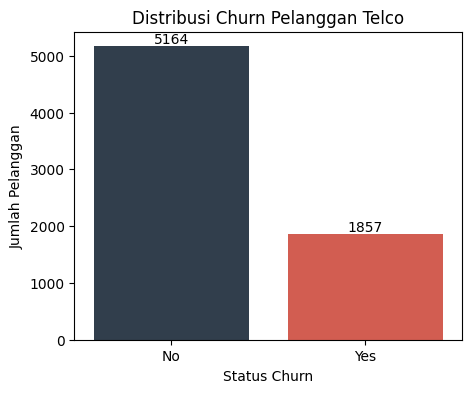

In [11]:
print("Jumlah tiap kelas:\n", telco['Churn'].value_counts())
print("\nPersentase tiap kelas:\n", telco['Churn'].value_counts(normalize=True).round(3) * 100)

plt.figure(figsize=(5,4))
ax = sns.countplot(x='Churn', hue='Churn', data=telco, palette=['#2C3E50', '#E74C3C'], legend=False)
plt.title('Distribusi Churn Pelanggan Telco')
plt.xlabel('Status Churn')
plt.ylabel('Jumlah Pelanggan')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')

plt.show()

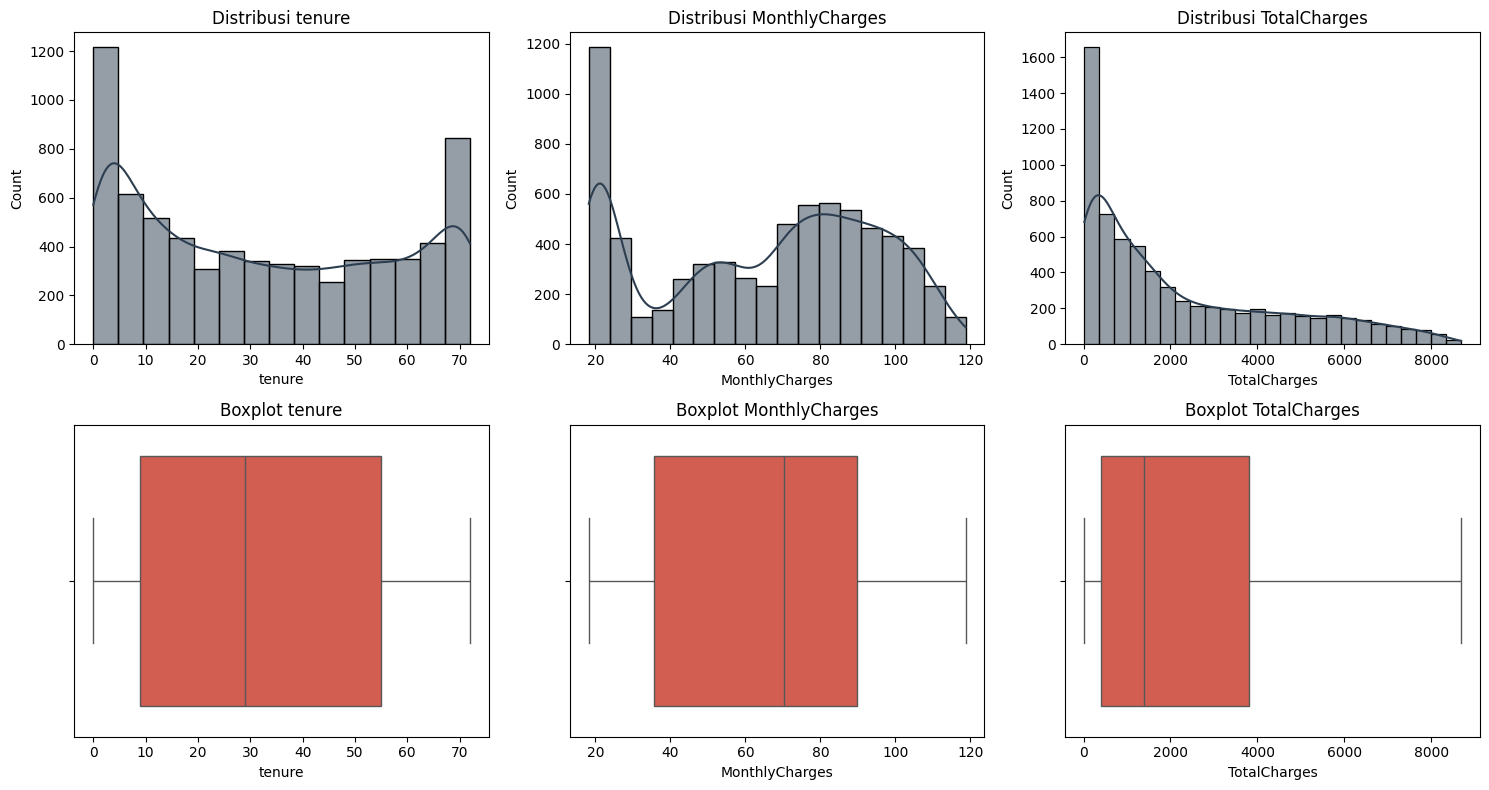

In [12]:
fitur_numerik = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, kolom in enumerate(fitur_numerik):
    sns.histplot(telco[kolom], kde=True, ax=axes[0, i], color='#2C3E50')
    axes[0, i].set_title(f'Distribusi {kolom}')

    sns.boxplot(x=telco[kolom], ax=axes[1, i], color='#E74C3C')
    axes[1, i].set_title(f'Boxplot {kolom}')

plt.tight_layout()
plt.show()

In [13]:
def cek_outlier_iqr(kolom):
    Q1 = telco[kolom].quantile(0.25)
    Q3 = telco[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outlier = telco[(telco[kolom] < batas_bawah) | (telco[kolom] > batas_atas)]
    print(f"\nKolom: {kolom}")
    print(f"Batas bawah: {batas_bawah:.2f}, Batas atas: {batas_atas:.2f}")
    print(f"Jumlah outlier: {len(outlier)}")

for kolom in fitur_numerik:
    cek_outlier_iqr(kolom)


Kolom: tenure
Batas bawah: -60.00, Batas atas: 124.00
Jumlah outlier: 0

Kolom: MonthlyCharges
Batas bawah: -45.48, Batas atas: 171.12
Jumlah outlier: 0

Kolom: TotalCharges
Batas bawah: -4674.68, Batas atas: 8887.52
Jumlah outlier: 0


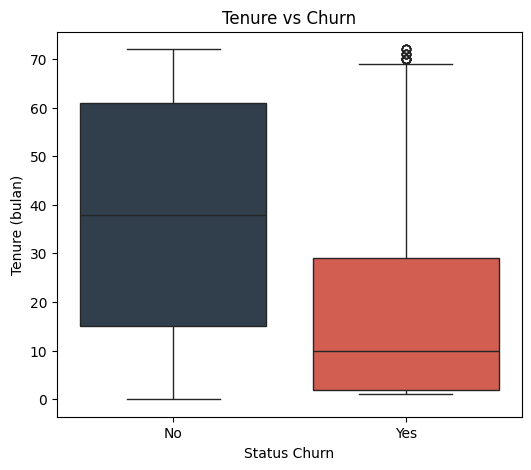

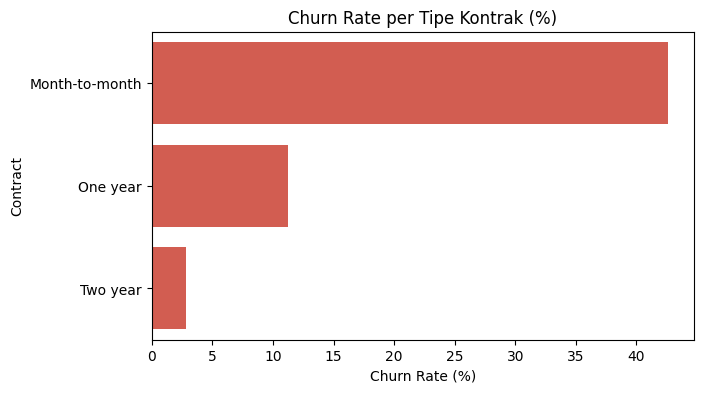

Churn rate per Contract (%):
 Contract
Month-to-month    42.6
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

Rata-rata tenure per status Churn:
 Churn
No     37.64
Yes    18.09
Name: tenure, dtype: float64

Rata-rata tenure per tipe Contract:
 Contract
Month-to-month    18.13
One year          42.04
Two year          56.74
Name: tenure, dtype: float64


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Boxplot tenure vs Churn
plt.figure(figsize=(6,5))
sns.boxplot(x='Churn', y='tenure', hue='Churn', data=telco, palette=['#2C3E50', '#E74C3C'], legend=False)
plt.title('Tenure vs Churn')
plt.xlabel('Status Churn')
plt.ylabel('Tenure (bulan)')
plt.show()

# 2. Churn rate per Contract
churn_rate_contract = telco.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).sort_values(ascending=False)

plt.figure(figsize=(7,4))
sns.barplot(x=churn_rate_contract.values, y=churn_rate_contract.index, color='#E74C3C')
plt.title('Churn Rate per Tipe Kontrak (%)')
plt.xlabel('Churn Rate (%)')
plt.show()

print("Churn rate per Contract (%):\n", churn_rate_contract.round(1))

# 3. Rata-rata tenure per status churn
print("\nRata-rata tenure per status Churn:\n", telco.groupby('Churn')['tenure'].mean().round(2))

# 4. Rata-rata tenure per tipe Contract
print("\nRata-rata tenure per tipe Contract:\n", telco.groupby('Contract')['tenure'].mean().round(2))